# Paper simulations: replications, figures and tables

Run top to bottom. Section 1 runs the replications once (about 2 hours for 10 seeds) and saves
`paper_reps.pkl`; every later section reads from that file, so after the first run, skip section 1
and run `rp.load` instead.

**What is replicated and what is not**
* Averaged over seeds (evidence): the test heatmap, the score tables, Con − GAS, the mean
  cumulative gain and the event study.
* From one representative seed, seed 0 (illustration): PIT histograms, ECDF minus uniform,
  Beta-parameter paths. Say so in the captions.

**Review additions (v3).** Every method and benchmark now runs under ONE configuration (section 0), all four methods are scored on `[EVAL_START, T)` with `EVAL_START = WARMUP + MIN_TRAIN` (the network is active from there), and section 2b reports:
* **M1** static baselines (eq. (9), expanding and rolling, both families) and GAS vs static at every discount factor,
* **M5** ablations of the composition (network only, linear head, no `median_loc`),
* **M6** coverage, width (sharpness), interval score, CRPS and a dependence-robust moment test,
* the **share of the oracle gap** captured: the log-score gap between the true DGP density and the raw pool.

Results go to a new file (`paper_reps_v3.pkl`), so the old replications are not overwritten.


In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path
from matplotlib.patches import Patch

import replicate_sim as rp
import sim_report as sr
import switch_event_study as es
from beta_parameter_plot import plot_beta_effective, plot_beta_params
from localised_metrics import _hac
from sim_report import INK

## 0. Settings

In [2]:
SEEDS      = range(10)       # replications
N_JOBS     = 4               # set to your number of performance cores
WARMUP     = 200
EVAL_START = WARMUP   # = WARMUP + MIN_TRAIN: network active, common window for all methods
ALPHA      = 0.95
LOC_DELTAS = (0.9, 0.2)      # discount factors with localized scores (KS, LogS, CRPS, IS, CSL)
MAIN_DELTA = 0.9             # scorecard / appendix discount factor
TVD_DELTA  = 0.2             # discount factor for the TV-dispersion mechanism figures
REPS_PATH  = "results/paper_reps_v5.pkl"   # new file: the v2 replications are kept

OUT = Path("figures/simulation"); OUT.mkdir(parents=True, exist_ok=True)
TAB = Path("tables");           TAB.mkdir(parents=True, exist_ok=True)

TVD = "Time_varying_dispersion"
SIX = [n for n in rp.SCENARIOS if n != TVD]
cmap = LinearSegmentedColormap.from_list("pass", ["#f4f3ef", "#9cc3ea", "#1d5fa8"])
d = sr.DELTAS.index(MAIN_DELTA)


def save_tex(text, name):
    (TAB / name).write_text(text)
    print(text)


# heatmap cells show the across-seed MEAN (e.g. 9.4 of 12): one-decimal version of the
# sim_report helper, so pit_panel prints decimals without editing sim_report.py
def _draw_tests_heatmap_mean(ax, counts, n_max=len(sr.DELTAS), cmap="Blues", ylabels=True, fontsize=12):
    Mx = np.asarray(counts, float)
    im = ax.imshow(Mx, cmap=cmap, vmin=0, vmax=n_max, aspect="auto")
    for i, j in np.ndindex(Mx.shape):
        ax.text(j, i, f"{Mx[i, j]:.1f}", ha="center", va="center", fontsize=fontsize,
                color="white" if Mx[i, j] >= 2 * n_max / 3 else "#2b2b2b")
    ax.axvline(3.5, color="white", lw=1.5, zorder=3)
    ax.axhline(0.5, color="white", lw=1.5, zorder=3)
    ax.set_xticks(range(len(sr.TEST_LABELS)), sr.TEST_LABELS, fontsize=fontsize)
    ax.set_yticks(range(len(sr.TEST_ROWS)), sr.TEST_ROWS if ylabels else [], fontsize=fontsize)
    ax.tick_params(length=0); ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    return im

sr._draw_tests_heatmap = _draw_tests_heatmap_mean

# ---- one configuration for every method and benchmark (review M4) ----
K_RQS        = 5
SLOW_SHRINK  = 1.0
FLOOR        = 1e-3
CON_KW       = dict(refit_every=50, hidden_size=4, num_epochs=300, learning_rate=1e-3, seed=42)
STATIC_REFIT = 50             # static baselines refitted as often as the network
ROLL_WINDOWS = (50, 100)     # rolling-window static baselines
STAT_DELTAS  = (MAIN_DELTA, TVD_DELTA)   # deltas with benchmarks, ablations and interval statistics

RUN_KW = dict(loc_deltas=LOC_DELTAS, warmup=WARMUP, eval_start=EVAL_START, alpha=ALPHA,
              K_rqs=K_RQS, slow_shrink=SLOW_SHRINK, floor=FLOOR,
              con_kw=CON_KW, static_refit_every=STATIC_REFIT, roll_windows=ROLL_WINDOWS,
              stat_deltas=STAT_DELTAS, ablations=True)


## 1. Run the replications (once)
Time one seed first, then run all seeds. Skip this section in later sessions.

In [3]:
# timing check: one scenario, one seed (the review additions roughly double the cost of a job)
# import time
# t0 = time.time()
# _ = rp.run_all(seeds=[0], scenarios=[TVD], n_jobs=1, **RUN_KW)
# print(f"one scenario, one seed: {time.time() - t0:.0f}s  "
#       f"(x {len(rp.SCENARIOS)} scenarios x {len(SEEDS)} seeds / {N_JOBS} jobs for the full run)")

In [4]:
%%time
reps = rp.run_all(seeds=SEEDS, n_jobs=N_JOBS, path=REPS_PATH, **RUN_KW)

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed: 15.6min
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed: 25.7min
/opt/anaconda3/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed: 45.5min
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed: 61.0min
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed: 104.3min
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed: 155.1min
[Parallel(n_jobs=4)]: Done  53 tasks      | elapsed: 234.4min
[Parallel(n_jobs=4)]: Done  70 out of  70 | elapsed: 329.9min finished


CPU times: user 16.1 s, sys: 9.43 s, total: 25.5 s
Wall time: 5h 29min 55s


## 2. Load the replications

In [5]:
reps = rp.load(REPS_PATH)
rep0 = rp.sr_results(reps, seed=min(SEEDS))          # representative seed for illustrations
print(len(reps), "jobs:", sorted({r["name"] for r in reps}), "| seeds:", sorted({r["seed"] for r in reps}))

70 jobs: ['Biased', 'Bimodal', 'Over_dispersed', 'Time_varying_dispersion', 'Time_varying_markov_switch', 'Trimodal', 'Under_dispersed'] | seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [6]:
SEED=0
repss = [r for r in rp.load(REPS_PATH) if r["seed"] == SEED]
res = rp.sr_results(repss, seed=SEED)                    # sim_report format: PITs + localized scores
print(len(repss), "scenarios:", [r["name"] for r in repss])


def test_counts(name):
    """5 x 6 integer counts: number of the 12 discount factors at which each test does not reject
    (rows raw, RQS-GAS, RQS-Con, Beta-GAS, Beta-Con; cols KS AD chi2 DH LB Berk.)."""
    r = next(r for r in repss if r["name"] == name)
    return np.stack([r["passed"][k].sum(axis=0) for k in rp.ORDER]).astype(int)


def con_vs_gas_hac(delta, names=None):
    """Con - GAS mean log-score gain on this seed's evaluation window with the HAC t-statistic,
    overall and (TV dispersion) by regime."""
    i = rp._didx(delta)
    rows = []
    for r in repss:
        if names is not None and r["name"] not in names:
            continue
        es_ = r["eval_start"]
        parts = {"all": np.ones(len(r["y"]) - es_, bool)}
        if r["state"] is not None:
            st = np.asarray(r["state"])[es_:]
            parts.update({"S=0": ~st, "S=1": st})
        for fam, (gas, con) in {"RQS": ("rg", "rc"), "Beta": ("bg", "bc")}.items():
            diff = (r["gain"][con][i] - r["gain"][gas][i])[es_:].astype(float)
            for lab, mask in parts.items():
                mean, t = _hac(diff[mask])
                rows.append(dict(scenario=r["name"], family=fam, regime=lab, con_minus_gas=mean, t_hac=t))
    return pd.DataFrame(rows)

7 scenarios: ['Over_dispersed', 'Under_dispersed', 'Biased', 'Bimodal', 'Trimodal', 'Time_varying_dispersion', 'Time_varying_markov_switch']


## 2b. Review benchmarks, ablations, sharpness and oracle share

All statistics are on each replication's evaluation window and averaged over seeds. **t (seeds)** is the across-seed $t$ (seeds are independent); **sig+ / sig− share** is the share of seeds whose own HAC Diebold–Mariano test is significant at 5% in that direction. **Oracle share** is the mean gain as a percentage of the log-score gap between the true DGP density and the raw pool. Recalibration cannot add information the pool lacks, so 100% is an upper bound and is not attainable.

In [7]:
print(reps[0]["settings"])                       # the configuration these replications used
MAIN_MODELS = ["raw", "s_rqs_exp", "s_beta_exp"] + \
              [f"s_{f}_roll{w}" for w in ROLL_WINDOWS for f in ("rqs", "beta")] + ["rg", "rc", "bg", "bc"]
ABL_MODELS = [f"{fam}:{a}" for fam in ("rc", "bc") for a in ("nn_only", "linear", "no_loc")]

{'K_rqs': 5, 'step_norm': 'coord', 'slow_shrink': 1.0, 'alpha': 0.95, 'floor': 0.001, 'warmup': 200, 'eval_start': 200, 'static_refit_every': 50, 'roll_windows': (50, 100), 'refit_every': 50, 'hidden_size': 4, 'num_epochs': 300, 'learning_rate': 0.001, 'seed': 42}


### Main results at $\delta=0.9$: methods against the raw pool and the static baselines (M1, M6)

In [68]:
# bench = rp.benchmark_table(reps, MAIN_DELTA, models=MAIN_MODELS)
# bench.drop(columns="key").style.format(precision=3).hide(axis="index")

In [9]:
save_tex(rp.benchmark_latex(reps, MAIN_DELTA, models=MAIN_MODELS, label="tab:sim_benchmarks"),
         "sim_benchmarks.tex")

\begin{table}[H]\centering\small
\begin{tabular}{ll r c c c c r}\toprule
Scenario & Model & $\Delta$LogS & Sig.\ gain & Cov. & Width/raw & Moment pass & Oracle \% \\ \midrule
Over dispersed & Raw pool & $+0.0000$ & -- & 0.97 & 1.00 & 0.0 & -- \\
 & Static-RQS (exp) & $+0.0612^{***}$ & 1.0 & 0.91 & 0.77 & 0.8 & 13 \\
 & Static-Beta (exp) & $+0.0691^{***}$ & 1.0 & 0.91 & 0.77 & 0.7 & 15 \\
 & Static-RQS (roll 50) & $-0.0786^{***}$ & 0.0 & 0.89 & 0.75 & 0.9 & -17 \\
 & Static-Beta (roll 50) & $+0.0531^{***}$ & 1.0 & 0.90 & 0.76 & 0.9 & 11 \\
 & Static-RQS (roll 100) & $+0.0066^{*}$ & 0.2 & 0.90 & 0.76 & 1.0 & 1 \\
 & Static-Beta (roll 100) & $+0.0623^{***}$ & 1.0 & 0.91 & 0.77 & 1.0 & 13 \\
 & RQS-GAS & $+0.0429^{***}$ & 1.0 & 0.92 & 0.81 & 0.4 & 9 \\
 & RQS-Con & $+0.0989^{***}$ & 1.0 & 0.92 & 0.77 & 0.6 & 21 \\
 & Beta-GAS & $+0.0534^{***}$ & 1.0 & 0.90 & 0.77 & 1.0 & 11 \\
 & Beta-Con & $+0.1285^{***}$ & 1.0 & 0.90 & 0.73 & 0.9 & 27 \\
\addlinespace
Under dispersed & Raw pool & $+0.000

### Does time variation help? GAS vs the static map of the same family 

At $\delta=0.9$ with per-seed HAC tests, then at every discount factor (across-seed $t$).

In [69]:
# pairs_tv = [("rg", "s_rqs_exp"), ("bg", "s_beta_exp")] + \
#            [(m, f"s_{f}_roll{w}") for w in ROLL_WINDOWS for m, f in (("rg", "rqs"), ("bg", "beta"))]
# rp.pairwise_table(reps, pairs_tv, MAIN_DELTA).style.format(precision=3).hide(axis="index")

### Ablations of the composition (M5): each variant against GAS of the same family

In [70]:
# pairs_abl = [("rc", "rg"), ("bc", "bg")] + \
#             [(f"{fam}:{a}", gas) for fam, gas in (("rc", "rg"), ("bc", "bg"))
#              for a in ("nn_only", "linear", "no_loc")]
# rp.pairwise_table(reps, pairs_abl, MAIN_DELTA).style.format(precision=3).hide(axis="index")

## 3. Main text — all scenarios

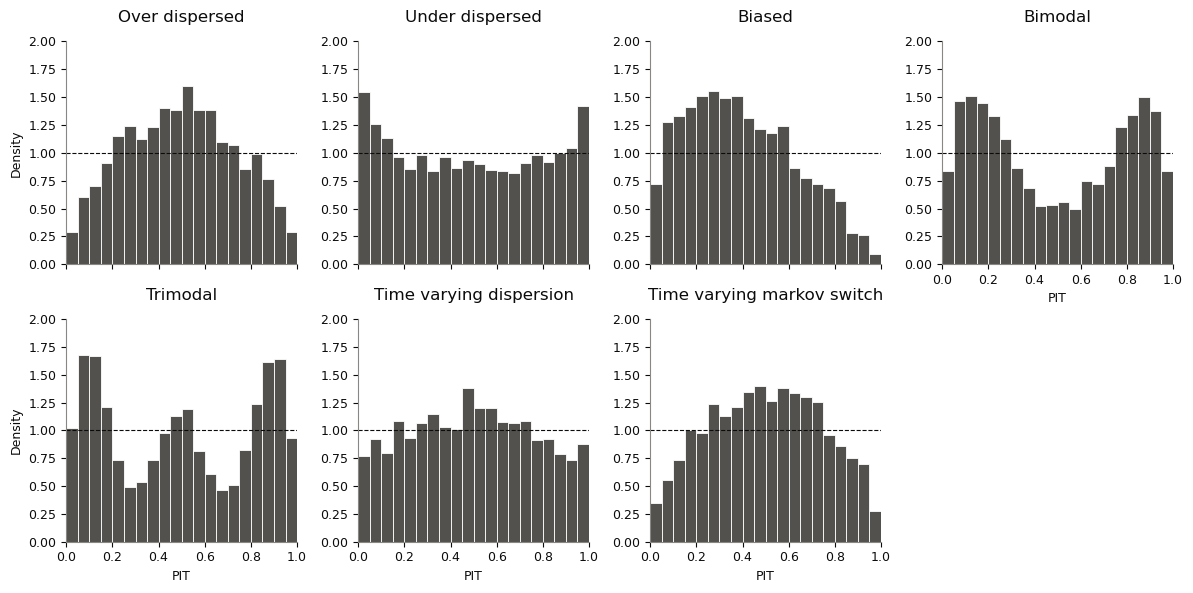

In [17]:
# raw-pool PIT histograms (seed 0)
sr.raw_hist_all(rep0, d, OUT / "raw_pit_all.pdf")

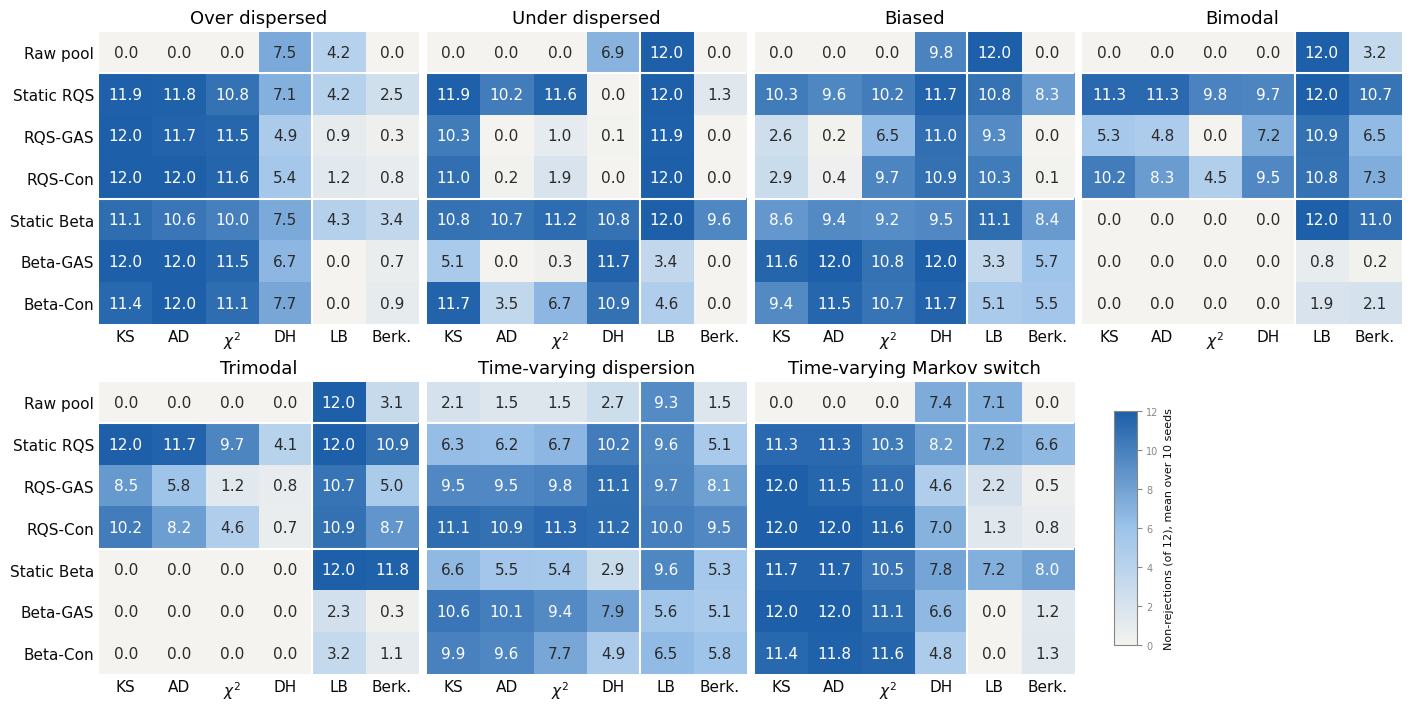

In [67]:
# tests passed after recalibration: mean over seeds of the number of the 12 discount factors not rejecting
rp.plot_pass_heatmaps(reps, path=OUT / "tests_heatmap_rep.pdf", cmap=cmap)

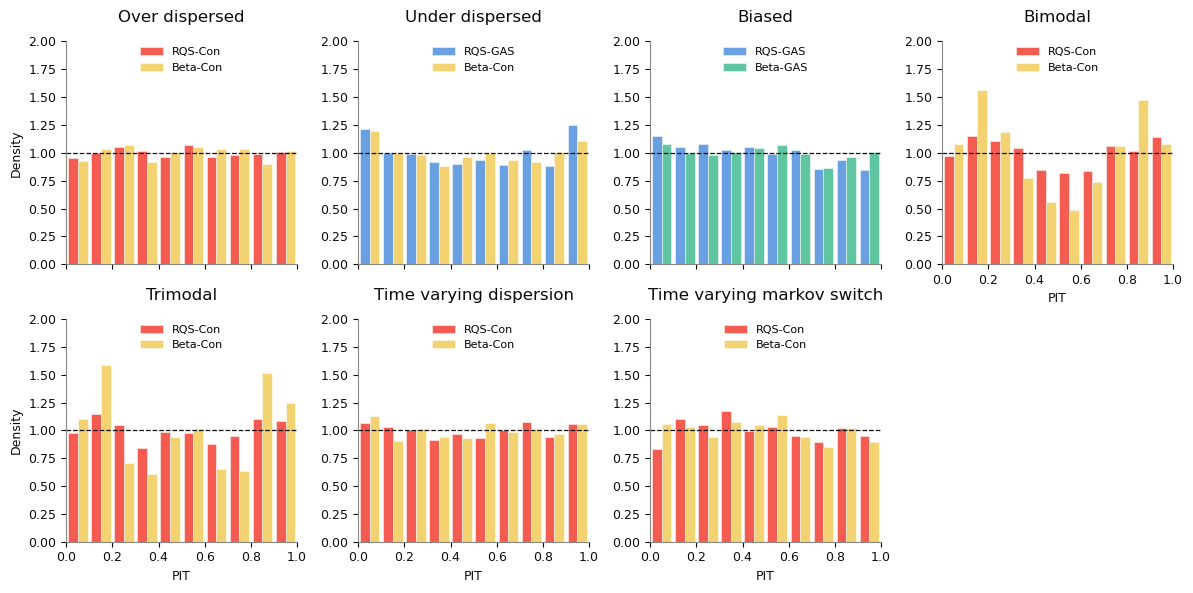

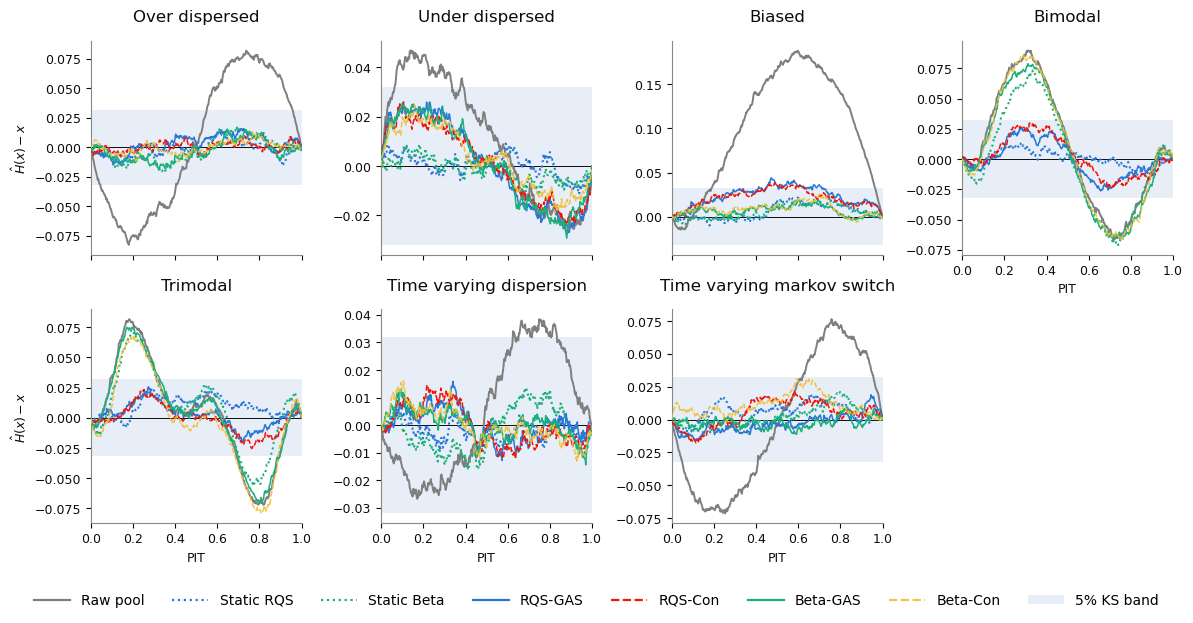

In [21]:
six0 = {k: rep0[k] for k in SIX}
sr.recal_hist_all(rep0, d, OUT / "recal_pit.pdf")       # recalibrated PIT histograms (seed 0)
sr.ecdf_dev_all(rep0, d, OUT / "ecdf_dev.pdf")          # ECDF minus uniform (seed 0)

In [65]:
save_tex(rp.scores_latex(reps, MAIN_DELTA, names=rp.SCENARIOS, label="tab:sim_scores_appendix"),
         "sim_scores_appendix.tex")

\begin{table}[H]\centering\small
\begin{tabular}{llccccccc}\toprule
Scenario & Metric & Raw pool & Static RQS & RQS-GAS & RQS-Con & Static Beta & Beta-GAS & Beta-Con \\ \midrule
Over dispersed & KS & $0.082$ [1.0] & $0.019$ [0.0] & $0.018$ [0.0] & $\mathbf{0.015}$ [0.0] & $0.023$ [0.1] & $0.016$ [0.0] & $0.020$ [0.1] \\
 & LogS & $-1.1912$ & $+0.0612^{***}$ & $+0.0429^{***}$ & $+0.0989^{***}$ & $+0.0691^{***}$ & $+0.0534^{***}$ & $\mathbf{+0.1285^{***}}$ \\
 & CRPS & $0.4059$ & $+0.0100^{***}$ & $+0.0057^{***}$ & $+0.0229^{***}$ & $+0.0100^{***}$ & $+0.0056^{***}$ & $\mathbf{+0.0308^{***}}$ \\
 & IS$_{90}$ & $3.2949$ & $+0.3299^{***}$ & $+0.2619^{***}$ & $+0.3605^{***}$ & $+0.3295^{***}$ & $+0.2777^{***}$ & $\mathbf{+0.3910^{***}}$ \\
 & IS$_{95}$ & $3.8463$ & $+0.4298^{***}$ & $+0.3298^{***}$ & $+0.4117^{***}$ & $+0.4426^{***}$ & $+0.3748^{***}$ & $\mathbf{+0.4629^{***}}$ \\
 & CSL$_{L}$ & $-0.2807$ & $+0.0187^{***}$ & $+0.0139^{***}$ & $+0.0315^{***}$ & $+0.0207^{***}$ & $+0.0168^{**

## 5. time-varying dispersion: Con vs GAS

In [25]:
def pairwise_latex(reps, delta=0.9, label="tab:sim-pairwise"):
    df = rp.con_vs_gas(reps, delta)
    df = df[df.regime == "all"]
    cols = [("con_minus_gas", "Con $-$ GAS"), ("gas_minus_static", "GAS $-$ static"),
            ("con_minus_static", "Con $-$ static")]
    R = int(df["R"].max())
    L = [r"\begin{table}[H]\centering\small",
         r"\begin{tabular}{ll" + "c" * len(cols) + r"}\toprule",
         "Scenario & Family & " + " & ".join(c for _, c in cols) + r" \\ \midrule"]
    for sc, g in df.groupby("scenario", sort=False):
        for j, (_, row) in enumerate(g.iterrows()):
            cells = []
            for key, _ in cols:
                s = rp._stars(row[f"t {key}"], R)
                cells.append(f"${row[key]:+.3f}" + (f"^{{{s}}}" if s else "") + f"$ ({row[f'wins {key}']})")
            L.append(f"{rp.DISPLAY.get(sc, sc) if j == 0 else ''} & {row.family} & " + " & ".join(cells) + r" \\")
        L.append(r"\addlinespace")
    L[-1] = r"\bottomrule\end{tabular}"
    L += [rf"\caption{{Mean log-score difference per period at $\alpha={delta}$, {R} replications. "
          r"Static: expanding-window static map of the same family. Stars: $t$-test across replications "
          r"at 10/5/1\%; in brackets, replications in which the first method is ahead.}",
          rf"\label{{{label}}}", r"\end{table}"]
    return "\n".join(L)

print(pairwise_latex(reps))

\begin{table}[H]\centering\small
\begin{tabular}{llccc}\toprule
Scenario & Family & Con $-$ GAS & GAS $-$ static & Con $-$ static \\ \midrule
Over dispersed & RQS & $+0.056^{***}$ (10/10) & $-0.018^{***}$ (0/10) & $+0.038^{***}$ (10/10) \\
 & Beta & $+0.075^{***}$ (10/10) & $-0.016^{***}$ (0/10) & $+0.059^{***}$ (10/10) \\
\addlinespace
Under dispersed & RQS & $-0.004^{***}$ (1/10) & $-0.018^{***}$ (0/10) & $-0.022^{***}$ (0/10) \\
 & Beta & $+0.006^{***}$ (10/10) & $-0.021^{***}$ (0/10) & $-0.016^{***}$ (0/10) \\
\addlinespace
Biased & RQS & $-0.003^{*}$ (2/10) & $-0.018^{***}$ (0/10) & $-0.022^{***}$ (0/10) \\
 & Beta & $+0.000$ (5/10) & $-0.015^{***}$ (0/10) & $-0.015^{***}$ (0/10) \\
\addlinespace
Bimodal & RQS & $+0.020^{***}$ (10/10) & $-0.016^{***}$ (0/10) & $+0.004$ (7/10) \\
 & Beta & $+0.013^{***}$ (10/10) & $-0.011^{***}$ (0/10) & $+0.002$ (5/10) \\
\addlinespace
Trimodal & RQS & $+0.058^{***}$ (10/10) & $-0.022^{***}$ (0/10) & $+0.036^{***}$ (10/10) \\
 & Beta & $+0.017^{**

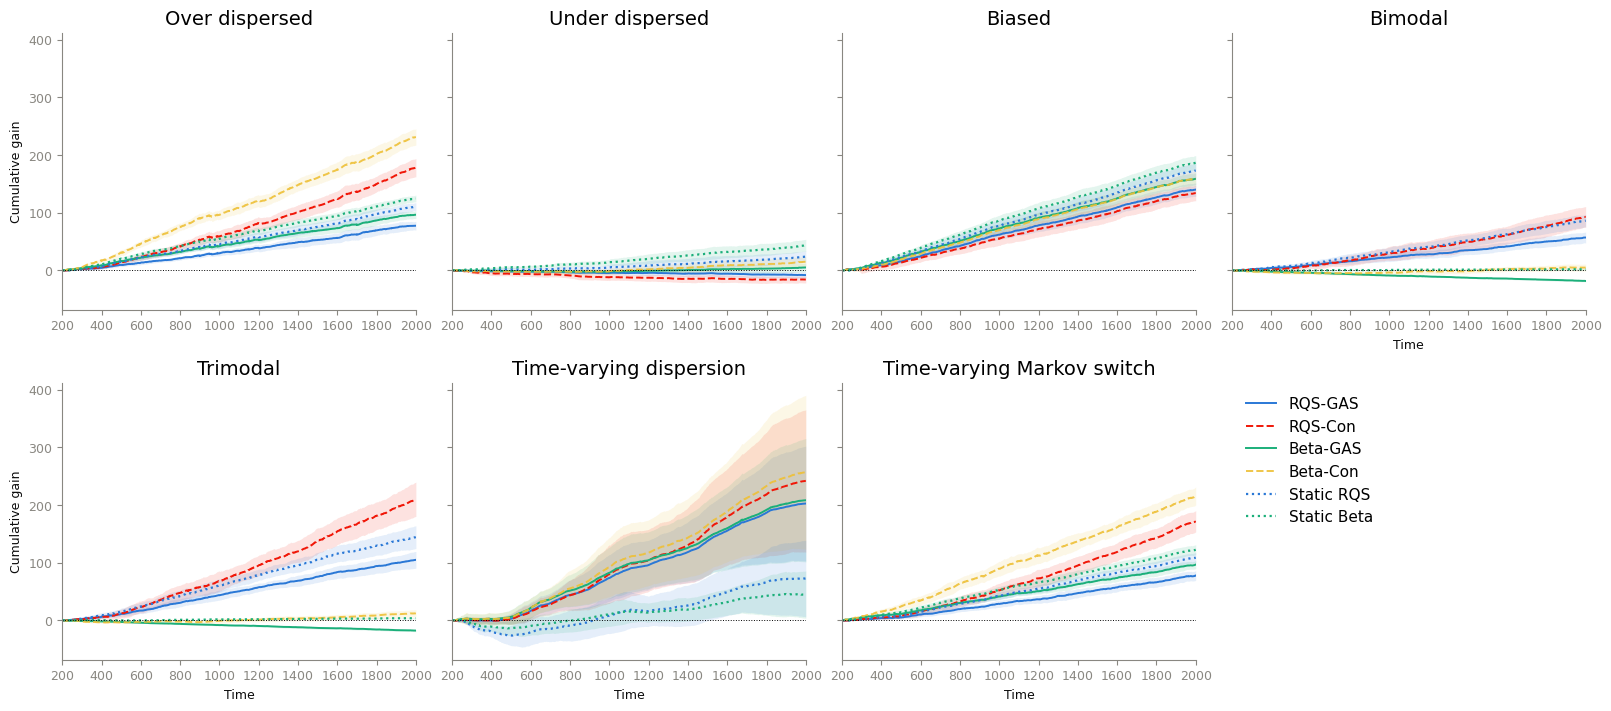

In [63]:
from scipy.stats import t as student_t

def plot_cum_gain_grid(reps, delta=MAIN_DELTA, difference=False, show_static=True, ncol=4,
                       panel=(4, 3), level=0.95, path=None, sharey=False):
    """Cumulative log-score gain over the raw pool for every scenario, one panel each.
    Several seeds in `reps` -> mean with a `level` band; one seed -> that seed's path.
    show_static=True adds the recursively refitted static RQS and static Beta maps (dotted).
    difference=True plots Con - GAS for each family instead (static lines not drawn)."""
    i = rp._didx(delta)
    names = [n for n in rp.SCENARIOS if any(r["name"] == n for r in reps)]
    nrow = int(np.ceil(len(names) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(panel[0] * ncol, (panel[1] * nrow + 1)),
                             squeeze=False, sharey=sharey, layout="constrained")
    G = lambda r, m: r["gain"][m][i]
    if difference:
        series = {"RQS: Con $-$ GAS":  (lambda r: G(r, "rc") - G(r, "rg"), rp.COLORS["rc"], "-"),
                  "Beta: Con $-$ GAS": (lambda r: G(r, "bc") - G(r, "bg"), "#1baf7a", "-")}
    else:
        series = {rp.LABELS[m]: ((lambda r, m=m: G(r, m)), rp.COLORS[m],
                                 "--" if m in ("rc", "bc") else "-") for m in rp.METHODS}
        if show_static:                       # static map of each family, same colour, dotted
            series["Static RQS"] = (lambda r: r["static_gain"]["rg"][i], rp.COLORS["rg"], ":")
            series["Static Beta"] = (lambda r: r["static_gain"]["bg"][i], rp.COLORS["bg"], ":")
    for k, (ax, name) in enumerate(zip(axes.flat, names)):
        rs = [r for r in reps if r["name"] == name]
        es_ = rs[0]["eval_start"]
        t = np.arange(es_, len(rs[0]["y"]))
        for lab, (f, col, ls) in series.items():
            C = np.stack([np.cumsum(np.asarray(f(r), float)[es_:]) for r in rs])
            mean = C.mean(0)
            if len(rs) > 1:
                h = student_t.ppf(0.5 + level / 2, len(rs) - 1) * C.std(0, ddof=1) / np.sqrt(len(rs))
                ax.fill_between(t, mean - h, mean + h, color=col, alpha=0.12, lw=0)
            ax.plot(t, mean, color=col, ls=ls, lw=1.6 if ls == ":" else 1.4,
                    label=lab if k == 0 else None)
        ax.axhline(0, color="black", lw=0.7, ls=":")
        ax.set_title(rp.DISPLAY.get(name, name), fontsize=14)
        ax.set_xlim(t[0], t[-1])
        if k % ncol == 0:
            ax.set_ylabel("Cumulative gain" + (" (Con $-$ GAS)" if difference else ""))
        if k >= len(names) - ncol:
            ax.set_xlabel("Time")
        for s in ("top", "right"):
            ax.spines[s].set_visible(False)
    for ax in axes.flat[len(names):]:
        ax.axis("off")
    spare = axes.flat[len(names)] if len(names) < axes.size else None
    handles, labels = axes.flat[0].get_legend_handles_labels()
    if spare is not None:                       # legend in the empty eighth panel
        spare.legend(handles, labels, loc="upper left", frameon=False, fontsize=11)
    else:
        fig.legend(handles, labels, loc="outside lower center", ncol=len(labels), frameon=False)
    if path:
        fig.savefig(path, dpi=300, bbox_inches="tight")


plot_cum_gain_grid(reps, path=OUT / "cum_gain_all.pdf",sharey=True)

mean                                  \
                        Beta Con-GAS Beta Con-static Beta GAS-static   
Biased                         0.000          -0.015          -0.015   
Bimodal                        0.013           0.002          -0.011   
Markov switching               0.066           0.052          -0.014   
Over dispersed                 0.075           0.059          -0.016   
Time-varying dispersion        0.027           0.118           0.091   
Trimodal                       0.017           0.005          -0.012   
Under dispersed                0.006          -0.016          -0.021   

                                                                   \
                        RQS Con-GAS RQS Con-static RQS GAS-static   
Biased                       -0.003         -0.022         -0.018   
Bimodal                       0.020          0.004         -0.016   
Markov switching              0.052          0.035         -0.017   
Over dispersed                0.056          0.038         -0.018   
Time-varying dispersion       0.022          0.094          0.072   
Trimodal                      0.058          0.036         -0.022   
Under dispersed              -0.004         -0.022         -0.018   

                                   t                                  \
                        Beta Con-GAS Beta Con-static Beta GAS-static   
Biased                         0.193          -9.070         -19.261   
Bimodal                        9.067           1.027         -43.104   
Markov switching              21.418          16.846         -15.529   
Over dispersed                21.180          17.270         -19.488   
Time-varying dispersion        3.641           4.684           4.752   
Trimodal                      10.678           3.358         -26.481   
Under dispersed                3.814          -9.494         -18.343   

                                                                   
                        RQS Con-GAS RQS Con-static RQS GAS-static  
Biased                       -1.879         -9.517        -15.602  
Bimodal                       7.495          1.282        -24.259  
Markov switching             12.695          8.229        -18.867  
Over dispersed               14.228          8.517        -15.145  
Time-varying dispersion       3.187          5.665          6.274  
Trimodal                     12.373          7.687        -13.121  
Under dispersed              -3.804        -11.068        -14.555

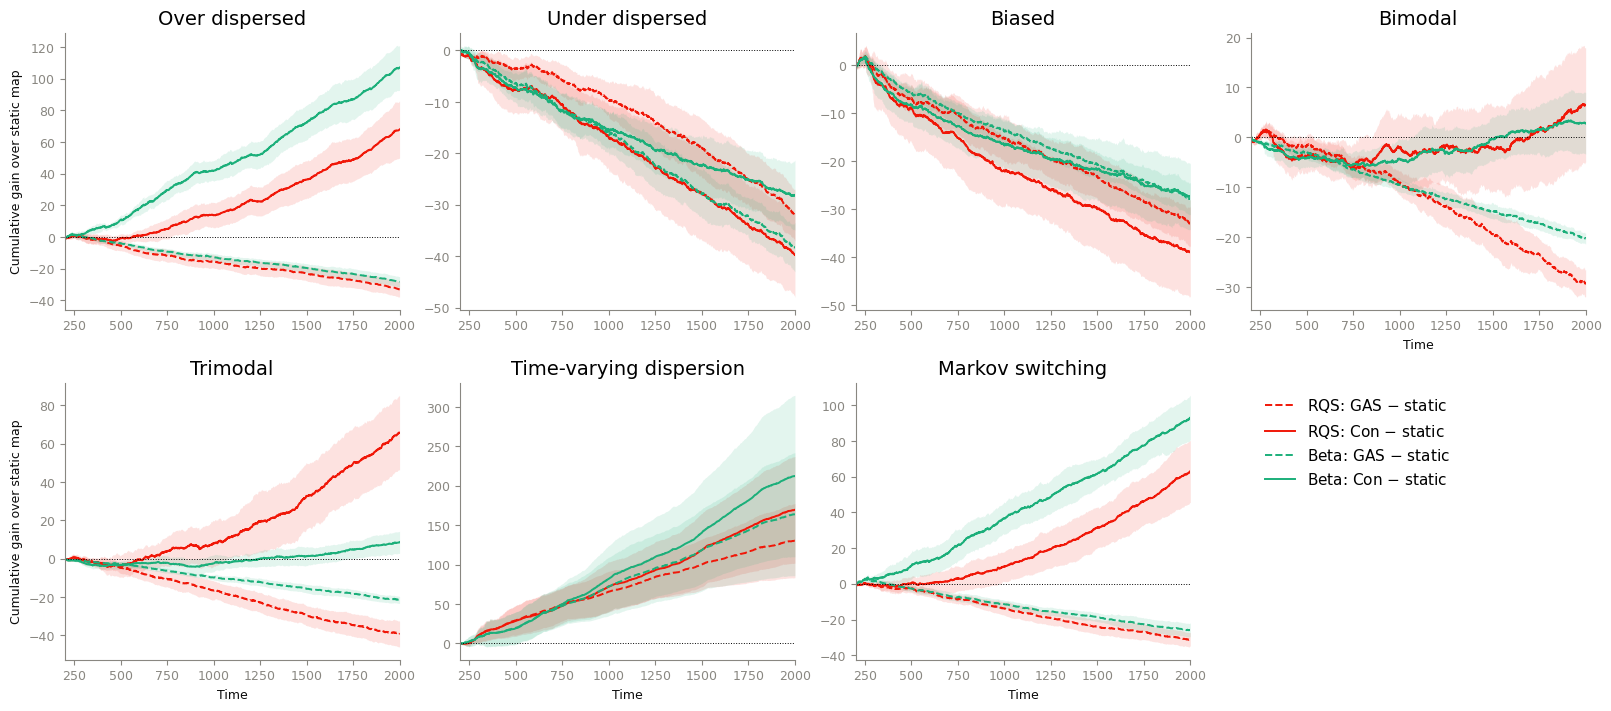

In [38]:
from scipy.stats import t as student_t

def plot_cum_gain_grid(reps, delta=MAIN_DELTA, compare="raw", difference=False, ncol=4, panel=(4, 3),
                       level=0.95, path=None, sharey=False):
    """Cumulative log-score gain per scenario, one panel each; several seeds -> mean with a
    `level` t-band across seeds.
    compare = 'raw'        each method's gain over the raw pool
              'con_gas'    Con - GAS for each family          (difference=True does the same)
              'vs_static'  GAS - static and Con - static for each family
              'all'        Con - GAS, GAS - static, Con - static
    Static = recursively refitted static map of the same family (r['static_gain'])."""
    if difference:
        compare = "con_gas"
    i = rp._didx(delta)
    names = [n for n in rp.SCENARIOS if any(r["name"] == n for r in reps)]
    nrow = int(np.ceil(len(names) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(panel[0] * ncol, (panel[1] * nrow + 1)),
                             squeeze=False, sharey=sharey, layout="constrained")

    G = lambda r, m: r["gain"][m][i]                  # gain over raw, full length
    S = lambda r, fam: r["static_gain"][fam][i]       # static map of family 'rg' (RQS) / 'bg' (Beta)
    c_rqs, c_beta = rp.COLORS["rc"], "#1baf7a"
    ser_con_gas = {"RQS: Con $-$ GAS":  (lambda r: G(r, "rc") - G(r, "rg"), c_rqs, "-"),
                   "Beta: Con $-$ GAS": (lambda r: G(r, "bc") - G(r, "bg"), c_beta, "-")}
    ser_static = {"RQS: GAS $-$ static":  (lambda r: G(r, "rg") - S(r, "rg"), c_rqs, "--"),
                  "RQS: Con $-$ static":  (lambda r: G(r, "rc") - S(r, "rg"), c_rqs, "-"),
                  "Beta: GAS $-$ static": (lambda r: G(r, "bg") - S(r, "bg"), c_beta, "--"),
                  "Beta: Con $-$ static": (lambda r: G(r, "bc") - S(r, "bg"), c_beta, "-")}
    if compare == "raw":
        series = {rp.LABELS[m]: ((lambda r, m=m: G(r, m)), rp.COLORS[m],
                                 "--" if m in ("rc", "bc") else "-") for m in rp.METHODS}
        ylab = "Cumulative gain over raw pool"
    elif compare == "con_gas":
        series, ylab = ser_con_gas, "Cumulative gain (Con $-$ GAS)"
    elif compare == "vs_static":
        series, ylab = ser_static, "Cumulative gain over static map"
    elif compare == "all":
        series = {**{k: (f, c, ":") for k, (f, c, _) in ser_con_gas.items()}, **ser_static}
        ylab = "Cumulative log-score difference"
    else:
        raise ValueError("compare must be 'raw', 'con_gas', 'vs_static' or 'all'")

    for k, (ax, name) in enumerate(zip(axes.flat, names)):
        rs = [r for r in reps if r["name"] == name]
        es_ = rs[0]["eval_start"]
        t = np.arange(es_, len(rs[0]["y"]))
        for lab, (f, col, ls) in series.items():
            C = np.stack([np.cumsum(np.asarray(f(r), float)[es_:]) for r in rs])
            mean = C.mean(0)
            if len(rs) > 1:
                h = student_t.ppf(0.5 + level / 2, len(rs) - 1) * C.std(0, ddof=1) / np.sqrt(len(rs))
                ax.fill_between(t, mean - h, mean + h, color=col, alpha=0.12, lw=0)
            ax.plot(t, mean, color=col, ls=ls, lw=1.4, label=lab if k == 0 else None)
        ax.axhline(0, color="black", lw=0.7, ls=":")
        ax.set_title(rp.DISPLAY.get(name, name), fontsize=14)
        ax.set_xlim(t[0], t[-1])
        if k % ncol == 0:
            ax.set_ylabel(ylab)
        if k >= len(names) - ncol:
            ax.set_xlabel("Time")
        for s in ("top", "right"):
            ax.spines[s].set_visible(False)
    for ax in axes.flat[len(names):]:
        ax.axis("off")
    spare = axes.flat[len(names)] if len(names) < axes.size else None
    handles, labels = axes.flat[0].get_legend_handles_labels()
    if spare is not None:                       # legend in the empty eighth panel
        spare.legend(handles, labels, loc="upper left", frameon=False, fontsize=11)
    else:
        fig.legend(handles, labels, loc="outside lower center", ncol=len(labels), frameon=False)
    if path:
        fig.savefig(path, dpi=300, bbox_inches="tight")


def final_gain_table(reps, delta=MAIN_DELTA):
    """Per-period mean difference over the evaluation window, mean across seeds, with the
    across-seed t statistic -- the numbers behind the figure."""
    i = rp._didx(delta)
    pairs = {"RQS Con-GAS": ("rc", "rg", None), "RQS GAS-static": ("rg", None, "rg"),
             "RQS Con-static": ("rc", None, "rg"), "Beta Con-GAS": ("bc", "bg", None),
             "Beta GAS-static": ("bg", None, "bg"), "Beta Con-static": ("bc", None, "bg")}
    rows = {}
    for name in [n for n in rp.SCENARIOS if any(r["name"] == n for r in reps)]:
        rs = [r for r in reps if r["name"] == name]
        for lab, (a, b, s) in pairs.items():
            d = np.array([((r["gain"][a][i] - (r["gain"][b][i] if b else r["static_gain"][s][i]))
                           [r["eval_start"]:]).astype(float).mean() for r in rs])
            se = d.std(ddof=1) / np.sqrt(len(d)) if len(d) > 1 else np.nan
            rows[(rp.DISPLAY.get(name, name), lab)] = {"mean": d.mean(), "t": d.mean() / se}
    return pd.DataFrame(rows).T.unstack(1).round(3)


plot_cum_gain_grid(reps, compare="vs_static", path=OUT / "cum_gain_vs_static.pdf")
final_gain_table(reps)

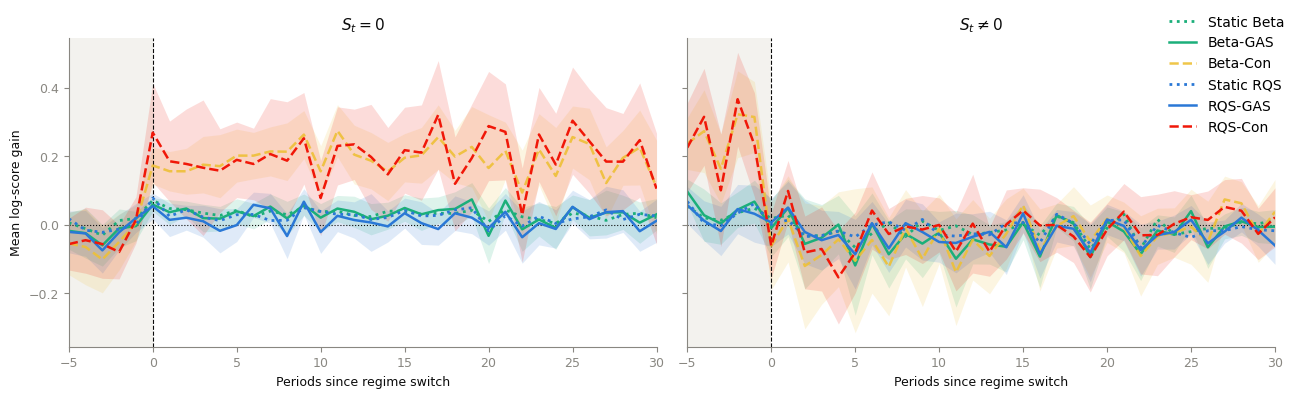

In [61]:
es.plot_event_study(es.runs_from_reps(reps, TVD, TVD_DELTA), eval_start=500, path=OUT / "event_study_tvd.pdf")

In [42]:
# (e) score tables at both discount factors
for delta in LOC_DELTAS:
    save_tex(rp.scores_latex(reps, delta, names=[TVD], label=f"tab:tvd_scores_{str(delta).replace('.', '')}"),
             f"tvd_scores_{str(delta).replace('.', '')}.tex")

\begin{table}[H]\centering\small
\begin{tabular}{llccccccc}\toprule
Scenario & Metric & Raw pool & Static RQS & RQS-GAS & RQS-Con & Static Beta & Beta-GAS & Beta-Con \\ \midrule
Time-varying dispersion & KS & $0.082$ [1.0] & $0.037$ [0.7] & $0.029$ [0.5] & $\mathbf{0.023}$ [0.1] & $0.051$ [0.7] & $0.024$ [0.3] & $0.025$ [0.3] \\
 & LogS & $-1.1518$ & $+0.0401^{**}$ & $+0.1125^{***}$ & $+0.1343^{***}$ & $+0.0247^{**}$ & $+0.1156^{***}$ & $\mathbf{+0.1426^{***}}$ \\
 & CRPS & $0.4290$ & $+0.0336^{***}$ & $+0.0476^{***}$ & $+0.0567^{***}$ & $+0.0237^{***}$ & $+0.0473^{***}$ & $\mathbf{+0.0593^{***}}$ \\
 & IS$_{90}$ & $4.0360$ & $+0.3181^{***}$ & $+0.9256^{***}$ & $+0.9972^{***}$ & $+0.3770^{***}$ & $+0.9992^{***}$ & $\mathbf{+1.0905^{***}}$ \\
 & IS$_{95}$ & $4.6458$ & $+0.2247^{***}$ & $+0.9310^{***}$ & $+0.9874^{***}$ & $+0.3603^{***}$ & $+1.1113^{***}$ & $\mathbf{+1.2149^{***}}$ \\
 & CSL$_{L}$ & $-0.2876$ & $+0.0187^{***}$ & $+0.0382^{***}$ & $+0.0437^{***}$ & $+0.0110^{**}$ & $+0.03

In [44]:
i = rp._didx(MAIN_DELTA)
rows = []
for r in reps: #_v2:                       # or reps_v2_all once the 10-seed rerun is done
    es_ = r["eval_start"]
    for fam, (gas, con) in {"RQS": ("rg", "rc"), "Beta": ("bg", "bc")}.items():
        dc = r["decomp"][con]
        rows.append(dict(scenario=r["name"], family=fam,
                         GAS_alone=dc["ll_gas_only_raw"][i][es_:].mean(),
                         Con_network=dc["ll_nn"][i][es_:].mean(),
                         Con_GAS_layer=dc["ll_gas"][i][es_:].mean()))
pd.DataFrame(rows).groupby(["scenario", "family"]).mean().round(4)

GAS_alone  Con_network  Con_GAS_layer
scenario                   family                                       
Biased                     Beta       0.0880       0.0215         0.0668
                           RQS        0.0777       0.0180         0.0563
Bimodal                    Beta      -0.0104       0.0110        -0.0086
                           RQS        0.0315       0.0401         0.0112
Over_dispersed             Beta       0.0534       0.0671         0.0614
                           RQS        0.0429       0.0640         0.0348
Time_varying_dispersion    Beta       0.1156       0.0310         0.1116
                           RQS        0.1125       0.0443         0.0900
Time_varying_markov_switch Beta       0.0536       0.0537         0.0660
                           RQS        0.0431       0.0657         0.0298
Trimodal                   Beta      -0.0100       0.0143        -0.0076
                           RQS        0.0582       0.0873         0.0292
Under_dispersed            Beta       0.0026       0.0146        -0.0064
                           RQS       -0.0047      -0.0030        -0.0061

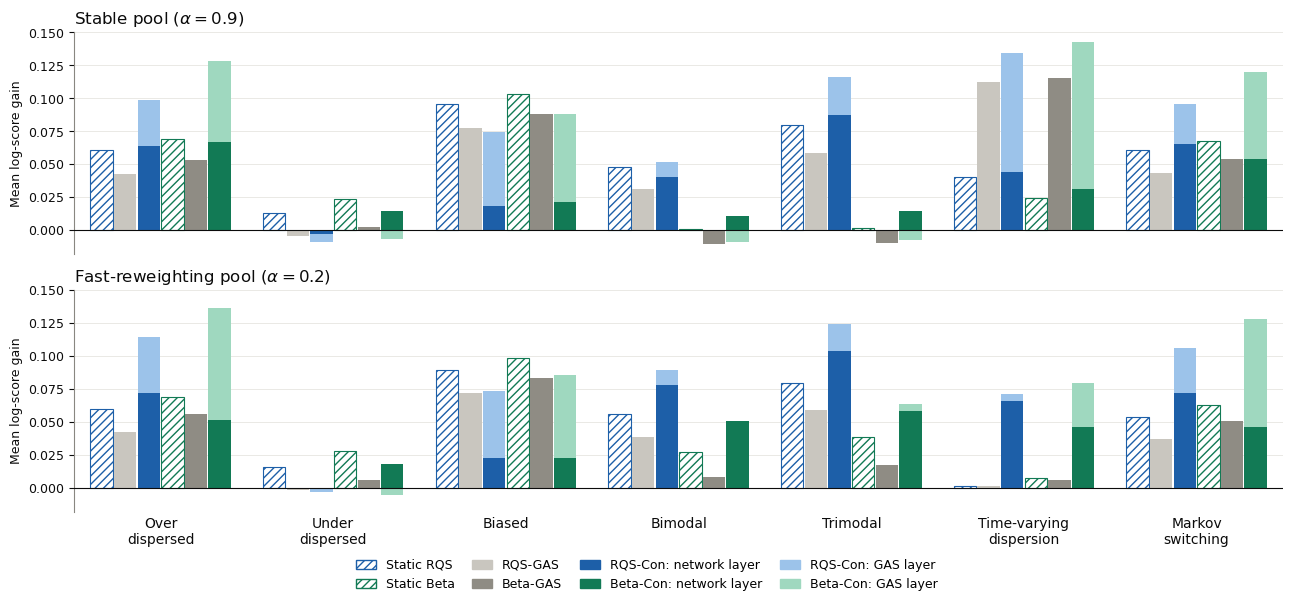

In [47]:
INK = "#0b0b0b"
# per family: (GAS alone, Con network layer, Con GAS layer) -- RQS in blues, Beta in greens
COLS = {"RQS": ("#c9c6bf", "#1d5fa8", "#9cc3ea"),
        "Beta": ("#8f8c84", "#127a55", "#9fd8bf")}
# static map of each family: white bar, hatched in the family's network-layer colour
STATIC_EDGE = {"RQS": "#1d5fa8", "Beta": "#127a55"}


def plot_layers(reps, deltas=(0.9, 0.2), path=None, orient="vertical", figsize=None, names=None,
                titles=None, show_static=True):
    """Per scenario and family: static map (hatched), GAS, and the composition split into network
    layer (dark) + GAS layer (light), which add up to its total (mean over the seeds in `reps`).
    One panel per discount factor in `deltas`, on a shared gain axis.
    orient='vertical'  : scenario names on the x axis, panels stacked in rows.
    orient='horizontal': scenario names on the y axis, panels side by side."""
    deltas = [deltas] if np.isscalar(deltas) else list(deltas)
    names = [n for n in rp.SCENARIOS if any(r["name"] == n for r in reps)] if names is None else list(names)
    fams = {"RQS": ("rg", "rc"), "Beta": ("bg", "bc")}
    if titles is None:
        titles = [rf"$\alpha = {d:g}$" for d in deltas]

    def layer_means(delta):
        i = rp._didx(delta)
        acc = {}
        for r in reps:
            es_ = r["eval_start"]
            for fam, (gas, con) in fams.items():
                dc = r["decomp"][con]
                acc.setdefault((r["name"], fam), []).append(
                    (float(r["static_gain"][gas][i][es_:].mean()),          # static map, same family
                     float(dc["ll_gas_only_raw"][i][es_:].mean()),
                     float(dc["ll_nn"][i][es_:].mean()),
                     float(dc["ll_gas"][i][es_:].mean())))
        return {k: np.asarray(v).mean(0) for k, v in acc.items()}

    horiz = orient == "horizontal"
    nd = len(deltas)
    nb = 3 if show_static else 2                          # bars per family
    h, gap = 0.36, 0.02
    step = 2 * nb * (h + gap) + 0.5
    offs = (np.arange(2 * nb) - (2 * nb - 1) / 2) * (h + gap)
    if horiz:
        fig, axes = plt.subplots(1, nd, figsize=figsize or (6.5 * nd, 9), sharex=True, sharey=True,
                                 squeeze=False)
    else:
        fig, axes = plt.subplots(nd, 1, figsize=figsize or (13, 6), sharex=True,
                                 sharey=True, squeeze=False)
    axes = axes.ravel()
    ticks = np.arange(len(names)) * step
    labels = [rp.DISPLAY.get(n, n) for n in names]

    for ax, delta, title in zip(axes, deltas, titles):
        M = layer_means(delta)

        def draw(pos, length, start, color, **extra):
            kw = dict(color=color, lw=0, zorder=2)
            kw.update(extra)
            if horiz:
                ax.barh(pos, length, h, left=start, **kw)
            else:
                ax.bar(pos, length, h, bottom=start, **kw)

        for k, n in enumerate(names):
            c0 = k * step
            for j, fam in enumerate(fams):
                st, g, nn, gl = M[(n, fam)]
                base = j * nb
                c_gas, c_nn, c_gl = COLS[fam]
                if show_static:
                    draw(c0 + offs[base], st, 0.0, "white", edgecolor=STATIC_EDGE[fam],
                         hatch="////", lw=0.8)
                    base += 1
                draw(c0 + offs[base], g, 0.0, c_gas)
                pc = c0 + offs[base + 1]
                pos = neg = 0.0                             # stack: positives from 0 up, negatives down
                for val, col in ((nn, c_nn), (gl, c_gl)):
                    start = pos if val >= 0 else neg + val
                    draw(pc, abs(val), start, col)
                    pos, neg = (pos + val, neg) if val >= 0 else (pos, neg + val)

        ax.set_title(title, fontsize=12, color=INK, loc="left")
        if horiz:
            ax.axvline(0, color=INK, lw=0.8, zorder=3)
            ax.set_yticks(ticks, labels, fontsize=10, color=INK)
            ax.set_ylim((len(names) - 0.5) * step, -0.5 * step)    # first scenario at the top
            ax.set_xlabel("Mean log-score gain", color=INK)
            ax.grid(axis="x", color="#e6e5e1", lw=0.6); ax.grid(axis="y", visible=False)
            for s in ("top", "right", "left"):
                ax.spines[s].set_visible(False)
            ax.tick_params(axis="y", length=0); ax.tick_params(axis="x", colors=INK)
        else:
            ax.axhline(0, color=INK, lw=0.8, zorder=3)
            wrap = lambda s: "\n".join(s.rsplit(" ", 1)) if len(s) > 12 else s
            ax.set_xticks(ticks, [wrap(l) for l in labels], fontsize=10, color=INK)
            ax.set_xlim(-0.5 * step, (len(names) - 0.5) * step)
            ax.set_ylabel("Mean log-score gain", color=INK)
            ax.grid(axis="y", color="#e6e5e1", lw=0.6); ax.grid(axis="x", visible=False)
            for s in ("top", "right", "bottom"):
                ax.spines[s].set_visible(False)
            ax.tick_params(axis="x", length=0); ax.tick_params(axis="y", colors=INK)
        ax.set_axisbelow(True)

    # legend: one column per item type, RQS above Beta
    items = []
    if show_static:
        items.append(("Static", lambda f: Patch(facecolor="white", edgecolor=STATIC_EDGE[f],
                                                hatch="////", label=f"Static {f}")))
    items += [(lab, (lambda f, j=j, lab=lab: Patch(color=COLS[f][j], label=f"{f}-{lab}")))
              for j, lab in enumerate(("GAS", "Con: network layer", "Con: GAS layer"))]
    handles = [mk(f) for _, mk in items for f in ("RQS", "Beta")]
    fig.legend(handles=handles, ncol=len(items), frameon=False, fontsize=9, loc="lower center",
               bbox_to_anchor=(0.5, -0.07), handlelength=1.6, columnspacing=1.4)
    fig.tight_layout(rect=(0, 0, 1, 0.94 if not horiz else 0.92))
    if path:
        fig.savefig(path, dpi=600, bbox_inches="tight")


plot_layers(reps, deltas=(0.9, 0.2),
            titles=[r"Stable pool ($\alpha = 0.9$)", r"Fast-reweighting pool ($\alpha = 0.2$)"],
            path=OUT / "layers_delta.pdf")